In [3]:
import pandas as pd
s = pd.read_excel('/content/Real estate valuation data set.xlsx')
s.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


### 1. Dataset Information and Statistics
Let's check the column datatypes, missing values, and overall descriptive statistics of the dataset.

In [4]:
# Print summary information of the dataset
s.info()

# Display descriptive statistics
display(s.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,207.500000,2013.148953,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,119.655756,0.281995,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,1.000000,2012.666667,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,104.250000,2012.916667,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,207.500000,2013.166667,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,310.750000,2013.416667,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,414.000000,2013.583333,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


### 2. Check for Missing Values

In [5]:
# Check if there are any missing values in each column
missing_values = s.isnull().sum()
print("Missing values per column:")
print(missing_values)

Missing values per column:
No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64


### 3. Visualizing Feature Correlations
Let's plot a correlation heatmap to see which variables are most strongly associated with the house prices.

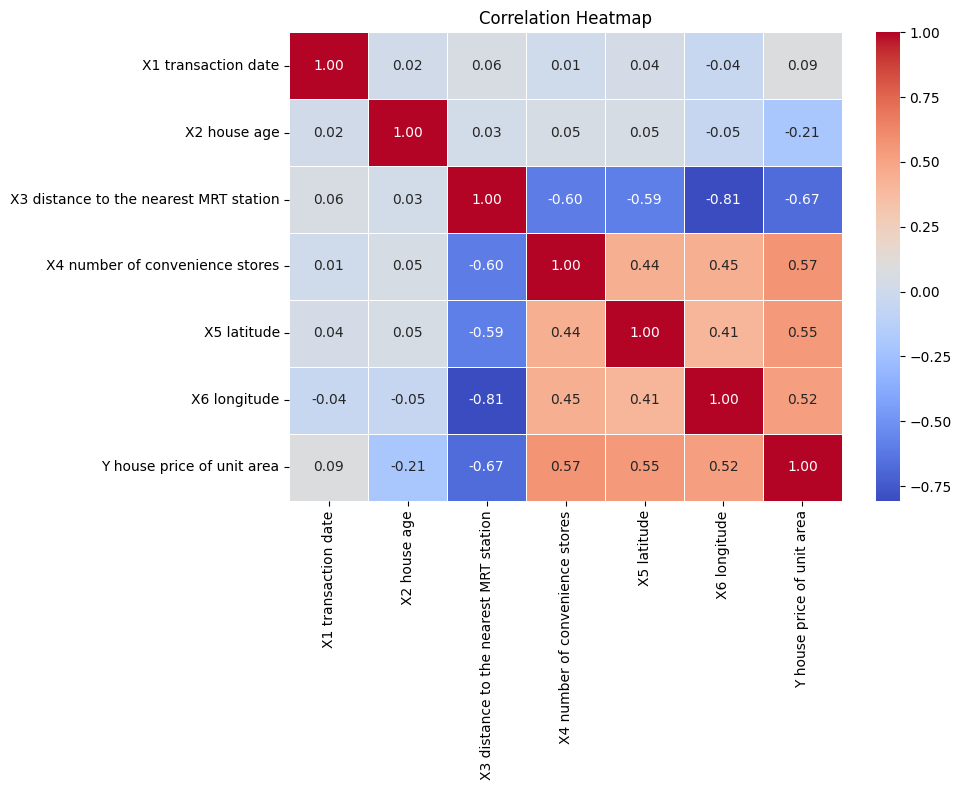

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix (excluding the index/No column if present)
corr_matrix = s.drop(columns=['No']).corr()

# Generate heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [7]:
# Calculate the average house age from the 'X2 house age' column
average_house_age = s['X2 house age'].mean()
print(f"The average house age is {average_house_age:.2f} years.")

The average house age is 17.71 years.


### 4. Comparing House Prices: Near vs. Far from MRT Station
We'll use **500 meters** as our threshold to segment the properties into two groups:
* **Near MRT:** distance $\le$ 500 meters
* **Far from MRT:** distance $>$ 500 meters

In [11]:
# Define threshold (500 meters)
threshold = 500

# Split the dataset into near and far
near_mrt = s[s['X3 distance to the nearest MRT station'] <= threshold]
far_mrt = s[s['X3 distance to the nearest MRT station'] > threshold]

# Calculate average prices
avg_price_near = near_mrt['Y house price of unit area'].mean()
avg_price_far = far_mrt['Y house price of unit area'].mean()

print(f"Average price for properties NEAR MRT (<= {threshold}m): {avg_price_near:.2f} per unit area (Count: {len(near_mrt)})")
print(f"Average price for properties FAR from MRT (> {threshold}m): {avg_price_far:.2f} per unit area (Count: {len(far_mrt)})")

Average price for properties NEAR MRT (<= 500m): 46.24 per unit area (Count: 211)
Average price for properties FAR from MRT (> 500m): 29.40 per unit area (Count: 203)


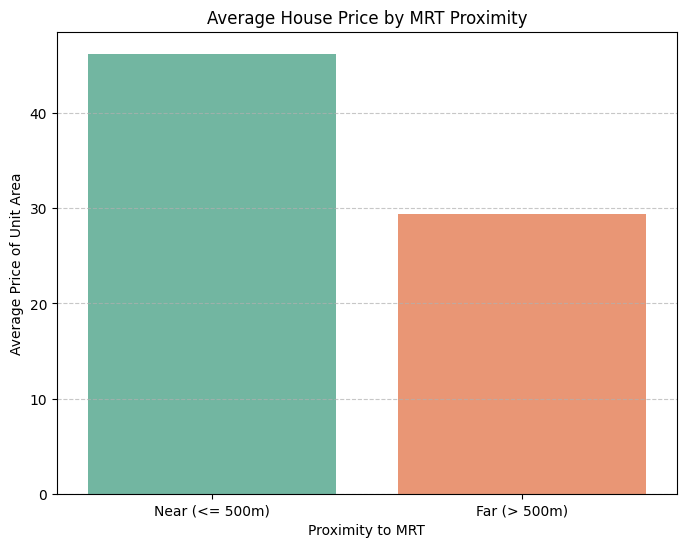

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a categorical column for visualization
s['MRT Proximity'] = s['X3 distance to the nearest MRT station'].apply(
    lambda x: f'Near (<= {threshold}m)' if x <= threshold else f'Far (> {threshold}m)'
)

# Plot the comparison
plt.figure(figsize=(8, 6))
sns.barplot(x='MRT Proximity', y='Y house price of unit area', data=s, estimator='mean', errorbar=None, palette='Set2', hue='MRT Proximity', legend=False)
plt.title('Average House Price by MRT Proximity')
plt.ylabel('Average Price of Unit Area')
plt.xlabel('Proximity to MRT')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 5. Impact of Convenience Stores on House Price
Let's calculate the average house price based on the number of nearby convenience stores (`X4 number of convenience stores`).

In [12]:
# Calculate the average price grouped by the number of convenience stores
store_price_analysis = s.groupby('X4 number of convenience stores')['Y house price of unit area'].agg(['mean', 'count']).reset_index()

# Rename columns for clarity
store_price_analysis.columns = ['Number of Convenience Stores', 'Average House Price', 'Record Count']
display(store_price_analysis)

,Number of Convenience Stores,Average House Price,Record Count
0,0,26.462687,67
1,1,31.839130,46
2,2,31.412500,24
3,3,29.536957,46
4,4,37.474194,31
5,5,44.729851,67
6,6,46.951351,37
7,7,43.848387,31
8,8,44.696667,30
9,9,51.732000,25


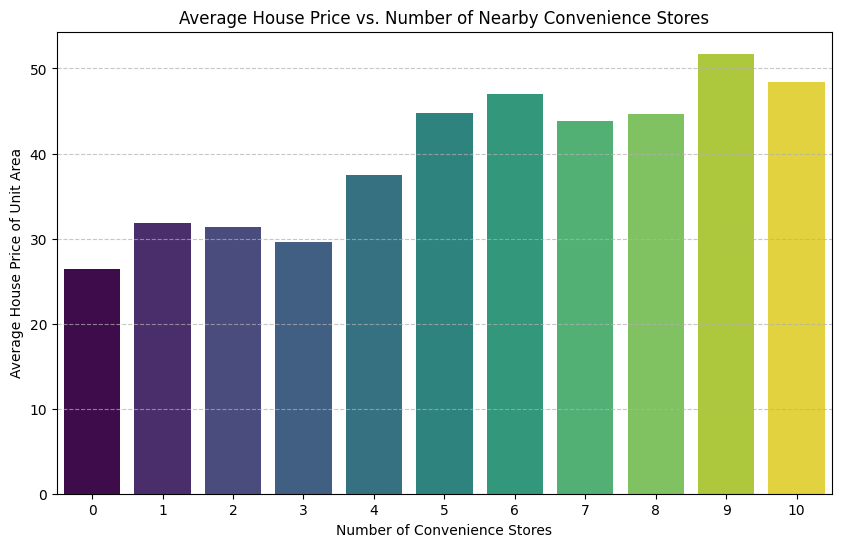

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the relationship between convenience stores and average price
plt.figure(figsize=(10, 6))
sns.barplot(x='Number of Convenience Stores', y='Average House Price', data=store_price_analysis, palette='viridis', hue='Number of Convenience Stores', legend=False)
plt.title('Average House Price vs. Number of Nearby Convenience Stores')
plt.xlabel('Number of Convenience Stores')
plt.ylabel('Average House Price of Unit Area')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 6. Finding the 10 Highest-Priced Records
Let's sort our dataset by the unit area price in descending order to identify the top 10 most expensive properties.

In [ ]:
# Sort by 'Y house price of unit area' in descending order and get the top 10
top_10_expensive = s.sort_values(by='Y house price of unit area', ascending=False).head(10)
display(top_10_expensive)

### 7. Missing Values and Duplicates Check
We will summarize our missing values scan and verify if there are any duplicate rows in the dataset.

In [15]:
# 1. Verify missing values again
missing_count = s.isnull().sum().sum()
print(f"Total missing values in the dataset: {missing_count}")

# 2. Check for duplicate rows (excluding the unique identifier 'No' to find true duplicate properties)
duplicate_rows = s.drop(columns=['No']).duplicated().sum()
print(f"Number of duplicate property records (excluding 'No'): {duplicate_rows}")

Total missing values in the dataset: 0
Number of duplicate property records (excluding 'No'): 0
